# Does the coding-SV result survive a looser call-rate filter?

The reported model keeps only SV events genotyped in **≥ 90 %** of the 231 founders. That is a stringent
floor, and the question is whether the headline depends on it. This notebook refits the whole model on
burdens rebuilt at **0.7** and **0.5** and reports what changes.

**What happens.** Relaxing the floor more than doubles the callable event set, and the pooled coding-SV
main effect goes from −1.49 %/variant (p = 4.9e-04) to −0.12 (p = 0.50). On its face the result does not
replicate.

**Why that reading is wrong.** The relaxed burden is not a noisier version of the same variable — it is a
mixture of two variables with opposite signs. §3 splits the coding burden by call-rate tier and fits both
tiers **simultaneously**: the events the reported model uses keep their effect exactly (−1.59 %/variant,
p = 1.7e-04) and the newly admitted events carry a *positive* one (+0.49 %/variant, p = 0.0061). The two
differ at p = 7.6e-06. Pooling them is what produces the null.

**What is held fixed.** Only the SV burden table changes between arms. Fitness, the SNP coding burden,
every covariate, and the kinship GRM — which is built from SNPs held at the 0.9 floor in all three arms —
are identical, so the comparison isolates the SV filter.

```r
y ~ snp_CDS + sv_CDS + sv_TE + sv_promoter + sv_intergenic + cactus
    + sv_CDS:bio1c + sv_TE:bio1c + sv_promoter:bio1c
    + obio1c + obio1c:bio1c
    + (1 | garden) + (1 | kin) + (0 + obio1c | garden)
    + (0 + sv_CDS | garden) + (0 + sv_TE | garden) + (0 + sv_promoter | garden)
```


In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

PA=f"{G}/final_models_pooled_all"
BASE="_x_obio1cobio1cbio1c_re0obio1cgarden"
CTX6=["CDS","UTR","intron","TE","promoter","intergenic"]
ARMS=[("","0.9  (reported)"),("_cr70","0.7"),("_cr50","0.5")]
ACOL={"":"#4A3B6B","_cr70":"#C46A10","_cr50":"#8C6D1F"}
BURD=["snp_CDS","sv_CDS","sv_TE","sv_promoter","sv_intergenic"]
SVT=["sv_CDS","sv_TE","sv_promoter"]
LAB={"snp_CDS":"SNPs, coding","sv_CDS":"SVs, coding","sv_TE":"SVs, reference TE",
     "sv_promoter":"SVs, promoter","sv_intergenic":"SVs, intergenic"}
def arm(cr,pool=""):
    S=f"{BASE}{'_'+pool if pool else ''}_refid{cr}"
    sc=pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c{'_'+pool if pool else ''}{cr}.csv").set_index("context")
    o={"co":pd.read_csv(f"{PA}/coef_M2p_reml{S}.csv").set_index("term"),
       "V":pd.read_csv(f"{PA}/vcov_M2p_reml{S}.csv",index_col=0),"sc":sc,
       "ll":pd.read_csv(f"{PA}/loglik_M2p_reml{S}.csv").iloc[0],"suf":S}
    o["pv"]={f"sv_{c}":100/(sc.loc[c,"sd_rate"]*sc.loc[c,"med_called"]) for c in sc.index}
    o["pv"]["snp_CDS"]=1.0
    g=lambda n: pd.read_csv(f"{PA}/loglik_{n}{S}.csv").logLik[0]
    # take the interaction terms from the fit itself: cds2 carries sv_nonCDS, sv6 carries sv_TE/sv_promoter
    o["LRT"]={t.split(":")[0]: stats.chi2.sf(2*(g("M2p_ml")-g(f"M2p_ml_drop_{t.split(':')[0]}")),1)
              for t in o["co"].index if t.endswith(":bio1c") and t.startswith("sv_")}
    return o
A={cr:arm(cr) for cr,_ in ARMS}
C2={cr:arm(cr,"cds2") for cr,_ in ARMS}
LONG=pd.read_csv(f"{G}/onestage_all/long.csv",dtype={"founder":str})
TECH=LONG.drop_duplicates("founder").set_index("founder").cactus
BUR={cr:pd.read_csv(f"{G}/founder_burden_event{cr}.csv",dtype={"founder":str}).set_index("founder")
     for cr,_ in ARMS}
def rate(B,ctxs):
    car=sum(B[f"ins_all_{c}_all"]+B[f"del_all_{c}_all"] for c in ctxs)
    cal=sum(B[f"called_ins_all_{c}_all"]+B[f"called_del_all_{c}_all"] for c in ctxs)
    return car/cal
print("Loaded the model at three founder call-rate floors, plus the two-tier fit.\n")
for cr,lab in ARMS:
    print(f"  floor {lab:16s} logLik {A[cr]['ll'].logLik:10.2f}  df {int(A[cr]['ll'].df)}  "
          f"singular {A[cr]['ll'].singular}")


Loaded the model at three founder call-rate floors, plus the two-tier fit.

  floor 0.9  (reported)  logLik  -11094.04  df 19  singular False
  floor 0.7              logLik  -11083.13  df 19  singular False
  floor 0.5              logLik  -11089.40  df 19  singular False


## 1 · What relaxing the floor lets in

How many SV events a typical founder is **genotyped at**, by genomic context, at each floor. This is the
denominator of the burden rate, so it is the quantity the filter actually controls.

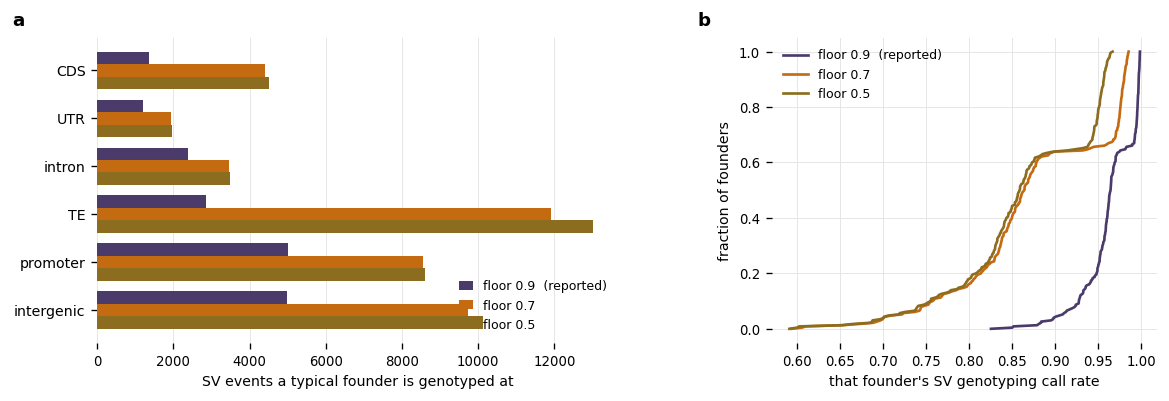

median SV events a founder is genotyped at, by context:

            0.9  (reported)    0.7    0.5
CDS                    1355   4408   4518
UTR                    1194   1928   1950
intron                 2373   3467   3483
TE                     2846  11919  13016
promoter               5001   8547   8602
intergenic             4993   9738  10131
ALL                   17762  40007  41700

  relative to the reported set: 0.9  (reported) 100%   0.7 225%   0.5 235%

  how similar is the burden itself across floors? (correlation across the 231 founders)
    coding      0.9 vs 0.7 r = +0.897   0.9 vs 0.5 r = +0.892   0.7 vs 0.5 r = +0.998
    non-coding  0.9 vs 0.7 r = +0.982   0.9 vs 0.5 r = +0.973   0.7 vs 0.5 r = +0.997


In [3]:

T=pd.DataFrame({lab:[int((BUR[cr][f"called_ins_all_{c}_all"]+BUR[cr][f"called_del_all_{c}_all"]).median())
                     for c in CTX6] for cr,lab in ARMS},index=CTX6)
fig,axs=plt.subplots(1,2,figsize=(11.4,3.3),gridspec_kw=dict(width_ratios=[1.35,1],wspace=0.34))
a=axs[0]; style(a); panel(a,"a",x=-0.14)
w=0.26
for j,(cr,lab) in enumerate(ARMS):
    a.barh(np.arange(len(CTX6))+(j-1)*w,T[lab],height=w,color=ACOL[cr],lw=0,label=f"floor {lab}")
a.set_yticks(range(len(CTX6))); a.set_yticklabels(CTX6,fontsize=8.5); a.invert_yaxis()
a.set_xlabel("SV events a typical founder is genotyped at",fontsize=8.5)
a.legend(fontsize=7.5,loc="lower right",handlelength=1.1)
a=axs[1]; style(a,axis="both"); panel(a,"b",x=-0.16)
fo=BUR[""].index
for cr,lab in ARMS:
    v=np.sort(BUR[cr].loc[fo,"callrate_sv"].to_numpy(float))
    a.plot(v,np.linspace(0,1,len(v)),color=ACOL[cr],lw=1.6,label=f"floor {lab}")
a.set_xlabel("that founder's SV genotyping call rate",fontsize=8.5)
a.set_ylabel("fraction of founders",fontsize=8.5); a.legend(fontsize=7.5,loc="upper left")
save(fig,"callrate_inputs",nb=True); plt.show()
T.loc["ALL"]=T.sum()
print("median SV events a founder is genotyped at, by context:\n"); print(T.to_string())
b=T.loc["ALL",ARMS[0][1]]
print("\n  relative to the reported set: "+"   ".join(
    f"{lab} {100*T.loc['ALL',lab]/b:.0f}%" for _,lab in ARMS))
print("\n  how similar is the burden itself across floors? (correlation across the 231 founders)")
for nm,cs in (("coding",["CDS"]),("non-coding",[c for c in CTX6 if c!="CDS"])):
    r9,r7,r5=(rate(BUR[cr].loc[fo],cs).to_numpy(float) for cr,_ in ARMS)
    print(f"    {nm:11s} 0.9 vs 0.7 r = {np.corrcoef(r9,r7)[0,1]:+.3f}   "
          f"0.9 vs 0.5 r = {np.corrcoef(r9,r5)[0,1]:+.3f}   "
          f"0.7 vs 0.5 r = {np.corrcoef(r7,r5)[0,1]:+.3f}")


## 2 · How genotyping success varies across the panel

Two distributions, because they turn out to explain most of what follows.

**(a)** The fraction of events that clear each floor, by context. Coding and reference-TE events are by
far the hardest to genotype — only **19.5 %** of coding events are called in ≥ 90 % of founders, against
55.8 % of intron events. The 0.9 filter is therefore not a mild trim in CDS; it keeps a fifth of them.

**(b, c)** Event size against genotyping success. Larger events are called in fewer founders, and in
**coding sequence this coupling is far steeper than anywhere else**: median coding event size rises
232 → 1,070 → 2,550 bp as the floor drops, while TE, promoter and intergenic sizes barely move. So the
events a relaxed floor newly admits in CDS are not a random sample of coding SVs — they are systematically
the big ones.

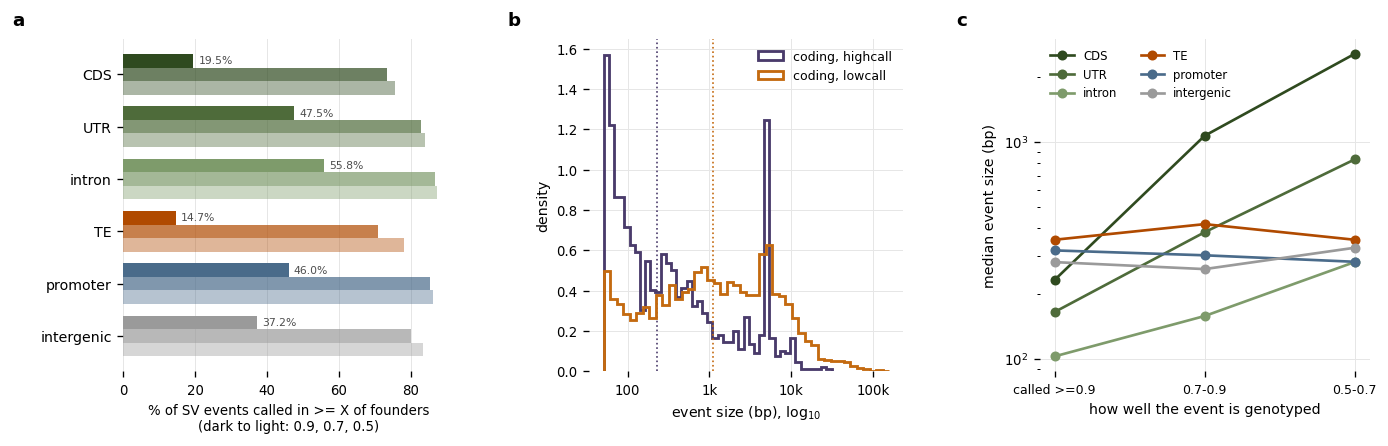

% OF SV EVENTS CALLED IN >= X OF THE 231 FOUNDERS

   context >=0.9 >=0.7 >=0.5 events
       CDS 19.5% 73.3% 75.7%  7,213
       UTR 47.5% 82.8% 83.9%  2,598
    intron 55.8% 86.8% 87.4%  4,392
        TE 14.7% 70.8% 78.1% 20,190
  promoter 46.0% 85.3% 86.1% 11,273
intergenic 37.2% 80.0% 83.4% 13,908


MEDIAN EVENT SIZE (bp) BY CONTEXT AND GENOTYPING BAND



   context called >=0.9 0.7-0.9 0.5-0.7
       CDS          232   1,070   2,550
       UTR          165     384     832
    intron          103     158     280
        TE          355     419     355
  promoter          317     301     281
intergenic          280     260     326

  coding size grows 11x across the bands; every other context is flat or shrinks.
  Spearman(size, n_called) among coding events: rho = -0.327


In [4]:

CAT=pd.read_csv(f"{G}/sv_event_catalog.csv")
AP=CAT[CAT.n_carriers>=2].copy()
CTXC={"CDS":"#2F4A1F","UTR":"#4E6B3A","intron":"#7E9B6B","TE":"#B04A00",
      "promoter":"#4A6B8A","intergenic":"#9A9A9A"}
FLOORS=[(208,"0.9"),(162,"0.7"),(116,"0.5")]
fig=plt.figure(figsize=(13.4,3.6))
gs=fig.add_gridspec(1,3,width_ratios=[1.05,1,1.05],wspace=0.42)
a=fig.add_subplot(gs[0,0]); style(a); panel(a,"a",x=-0.30)
w=0.26
for j,(thr,lab) in enumerate(FLOORS):
    vals=[100*(AP[AP.context==c].n_called>=thr).mean() for c in CTX6]
    a.barh(np.arange(len(CTX6))+(j-1)*w,vals,height=w,lw=0,
           color=[CTXC[c] for c in CTX6],alpha=1.0-0.30*j)
    if j==0:
        for i,v in enumerate(vals):
            a.annotate(f"{v:.1f}%",xy=(v,i-w),xytext=(3,0),textcoords="offset points",
                       va="center",fontsize=6.5,color="0.3")
a.set_yticks(range(len(CTX6))); a.set_yticklabels(CTX6,fontsize=8.5); a.invert_yaxis()
a.set_xlabel("% of SV events called in >= X of founders\n(dark to light: 0.9, 0.7, 0.5)",fontsize=8)
a=fig.add_subplot(gs[0,1]); style(a,axis="both"); panel(a,"b",x=-0.22)
D=AP[(AP.context=="CDS")&(AP.n_called>=116)].copy()
D["tier"]=np.where(D.n_called>=208,"highcall","lowcall")
for t,c in (("highcall","#4A3B6B"),("lowcall","#C46A10")):
    v=np.log10(D.size_bp[D.tier==t].to_numpy())
    a.hist(v,bins=44,density=True,histtype="step",lw=1.7,color=c,label=f"coding, {t}")
    a.axvline(np.median(v),color=c,lw=1.0,ls=":")
a.set_xlabel("event size (bp), log$_{10}$",fontsize=8.5); a.set_ylabel("density",fontsize=8.5)
a.legend(fontsize=7.5,loc="upper right")
a.set_xticks([2,3,4,5]); a.set_xticklabels(["100","1k","10k","100k"],fontsize=8)
a=fig.add_subplot(gs[0,2]); style(a,axis="both"); panel(a,"c",x=-0.22)
BANDS=[(208,231,"called >=0.9"),(162,207,"0.7-0.9"),(116,161,"0.5-0.7")]
for c in CTX6:
    g=AP[AP.context==c]
    med=[g[(g.n_called>=lo)&(g.n_called<=hi)].size_bp.median() for lo,hi,_ in BANDS]
    a.plot(range(len(BANDS)),med,"o-",color=CTXC[c],lw=1.6,ms=5,label=c)
a.set_xticks(range(len(BANDS))); a.set_xticklabels([l for _,_,l in BANDS],fontsize=7.5)
a.set_yscale("log"); a.set_ylabel("median event size (bp)",fontsize=8.5)
a.set_xlabel("how well the event is genotyped",fontsize=8.5)
a.legend(fontsize=7,ncol=2,loc="upper left")
save(fig,"callrate_distributions",nb=True); plt.show()
print("% OF SV EVENTS CALLED IN >= X OF THE 231 FOUNDERS\n")
print(pd.DataFrame([{"context":c,**{f">={l}":f"{100*(AP[AP.context==c].n_called>=t).mean():.1f}%"
                     for t,l in FLOORS},"events":f"{int((AP.context==c).sum()):,}"}
                    for c in CTX6]).to_string(index=False))
print("\n\nMEDIAN EVENT SIZE (bp) BY CONTEXT AND GENOTYPING BAND\n")
print(pd.DataFrame([{"context":c,**{l:f"{AP[(AP.context==c)&(AP.n_called>=lo)&(AP.n_called<=hi)].size_bp.median():,.0f}"
                     for lo,hi,l in BANDS}} for c in CTX6]).to_string(index=False))
print("\n  coding size grows 11x across the bands; every other context is flat or shrinks.")
print(f"  Spearman(size, n_called) among coding events: "
      f"rho = {stats.spearmanr(D.size_bp,D.n_called).correlation:+.3f}")


### The same size distribution, stacked by what the events are

Panel (b) above shows coding events only, and as densities — so it says how the two tiers differ in shape
but not what they are made of. These are the same size axis as counts, stacked.

**Top row: every context.** The size axis is dominated by different things at different scales, and the two
tiers are made of different mixtures.

**Bottom row: coding events only, stacked by sequence class** — the classification that would carry a
"these are really TEs" explanation. It does not: `te_derived` is a similar share of both tiers, and the
tiers separate on size, not on class.

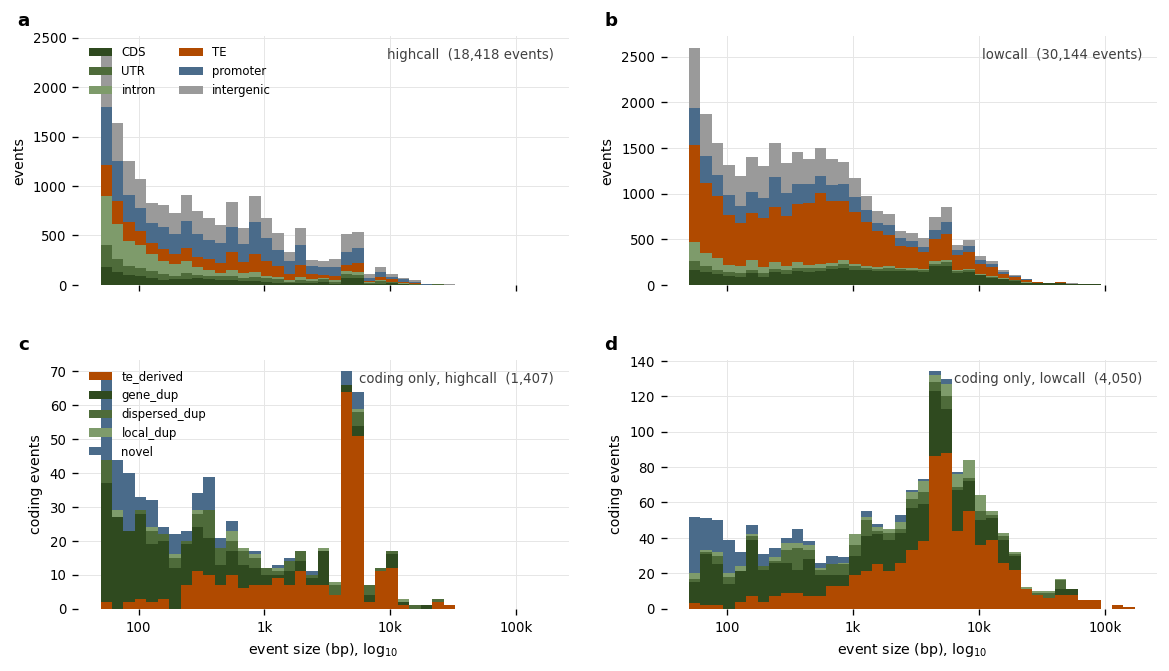

COMPOSITION BY CONTEXT, within each call tier (% of that tier's events)

tier        highcall  lowcall
context                      
CDS              7.6     13.4
UTR              6.7      3.1
intron          13.3      4.6
TE              16.1     42.5
promoter        28.1     15.0
intergenic      28.1     21.3


CODING EVENTS ONLY -- composition by sequence class (%)

tier           highcall  lowcall
seq_class                       
dispersed_dup       9.7      7.8
gene_dup           35.1     32.2
local_dup           2.1      6.1
novel              15.9      9.5
te_derived         37.2     44.5


MEDIAN SIZE (bp) by context and tier -- where the tiers actually separate

            highcall  lowcall
CDS            232.0   1100.0
UTR            165.0    392.0
intron         103.0    158.0
TE             355.0    411.0
promoter       317.0    299.0
intergenic     280.0    264.0


In [5]:

SQC={"te_derived":"#B04A00","gene_dup":"#2F4A1F","dispersed_dup":"#4E6B3A",
     "local_dup":"#7E9B6B","novel":"#4A6B8A"}
SQ=[k for k in SQC if k in set(AP.seq_class.dropna())]
AP2=AP[AP.n_called>=116].copy()
AP2["tier"]=np.where(AP2.n_called>=208,"highcall","lowcall")
EDG=np.linspace(np.log10(50),np.log10(AP2.size_bp.max()),40)
ctr=0.5*(EDG[1:]+EDG[:-1]); wid=np.diff(EDG)
fig,axs=plt.subplots(2,2,figsize=(11.6,6.2),sharex=True,
                     gridspec_kw=dict(hspace=0.30,wspace=0.20))
for j,tier in enumerate(("highcall","lowcall")):
    T=AP2[AP2.tier==tier]
    a=axs[0,j]; style(a,axis="both"); panel(a,"ab"[j],x=-0.10)
    bot=np.zeros(len(ctr))
    for c in CTX6:
        h,_=np.histogram(np.log10(T.size_bp[T.context==c]),bins=EDG)
        a.bar(ctr,h,width=wid,bottom=bot,color=CTXC[c],lw=0,label=c); bot+=h
    a.annotate(f"{tier}  ({len(T):,} events)",xy=(0.97,0.95),xycoords="axes fraction",
               ha="right",va="top",fontsize=8,color="0.25")
    a.set_ylabel("events",fontsize=8.5)
    if j==0: a.legend(fontsize=7,ncol=2,loc="upper left")
    a=axs[1,j]; style(a,axis="both"); panel(a,"cd"[j],x=-0.10)
    Tc=T[T.context=="CDS"]; bot=np.zeros(len(ctr))
    for k in SQ:
        h,_=np.histogram(np.log10(Tc.size_bp[Tc.seq_class==k]),bins=EDG)
        a.bar(ctr,h,width=wid,bottom=bot,color=SQC[k],lw=0,label=k); bot+=h
    a.annotate(f"coding only, {tier}  ({len(Tc):,})",xy=(0.97,0.95),xycoords="axes fraction",
               ha="right",va="top",fontsize=8,color="0.25")
    a.set_ylabel("coding events",fontsize=8.5)
    a.set_xlabel("event size (bp), log$_{10}$",fontsize=8.5)
    a.set_xticks([2,3,4,5]); a.set_xticklabels(["100","1k","10k","100k"],fontsize=8)
    if j==0: a.legend(fontsize=7,loc="upper left")
save(fig,"callrate_size_stacked",nb=True); plt.show()
print("COMPOSITION BY CONTEXT, within each call tier (% of that tier's events)\n")
print(pd.crosstab(AP2.context,AP2.tier,normalize="columns").mul(100).round(1)
        .reindex(CTX6).to_string())
print("\n\nCODING EVENTS ONLY -- composition by sequence class (%)\n")
CC_=AP2[AP2.context=="CDS"]
print(pd.crosstab(CC_.seq_class,CC_.tier,normalize="columns").mul(100).round(1).to_string())
print("\n\nMEDIAN SIZE (bp) by context and tier -- where the tiers actually separate\n")
print(pd.DataFrame({t:[g[g.context==c].size_bp.median() for c in CTX6]
                    for t,g in AP2.groupby("tier")},index=CTX6).round(0).to_string())


## 3 · The model at each floor

Every fixed effect of the reported model, refit on each burden table. **(a)** burden main effects,
**(b)** the garden-temperature interactions (likelihood-ratio tested). Filled markers are p < 0.05.

The coding main effect is the one that moves: it collapses toward zero at both relaxed floors, while
`snp_CDS` — the matched SNP burden, which the filter never touched — gets *stronger*. That rules out a
general loss of power and points at the SV burden variable itself.

The interactions do **not** collapse. Coding × temperature stays significant at every floor.

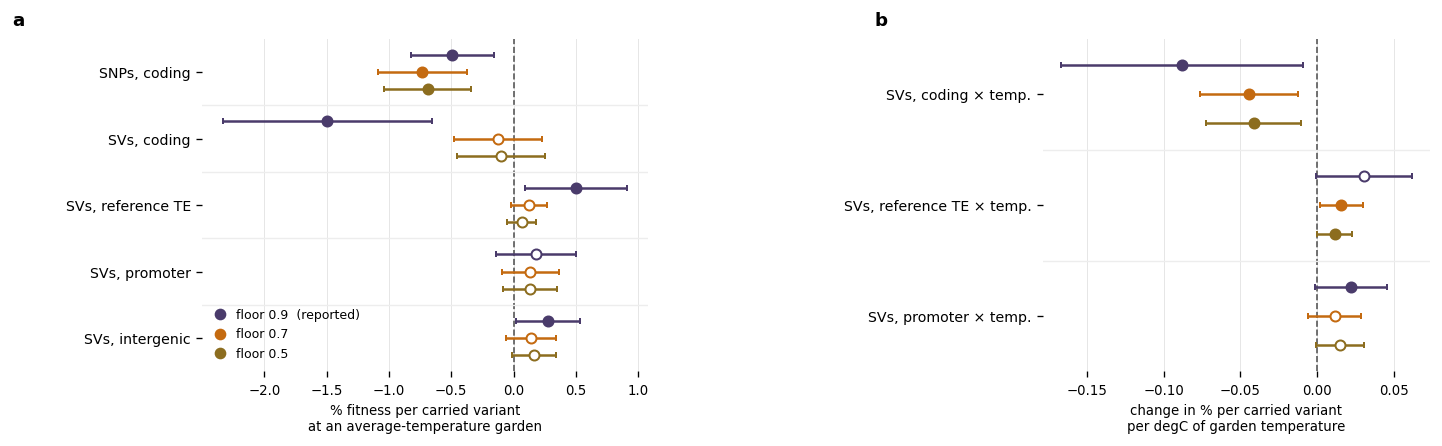


BURDEN MAIN EFFECTS, % fitness per carried variant

             term     0.9  (reported)                  0.7                  0.5
     SNPs, coding -0.4928 (p 0.00365) -0.7318 (p 6.54e-05) -0.6875 (p 0.000114)
      SVs, coding -1.4949 (p 0.00049)    -0.1249 (p 0.484)    -0.1034 (p 0.566)
SVs, reference TE  +0.5036 (p 0.0161)   +0.1227 (p 0.0923)    +0.0642 (p 0.294)
    SVs, promoter   +0.1791 (p 0.277)    +0.1355 (p 0.246)    +0.1306 (p 0.236)
  SVs, intergenic  +0.2771 (p 0.0358)    +0.1402 (p 0.179)   +0.1631 (p 0.0684)

INTERACTIONS, % per carried variant per degC (LRT p)

             term     0.9  (reported)                 0.7                0.5
      SVs, coding -0.0883 (p 0.00829) -0.0443 (p 0.00752) -0.0414 (p 0.0095)
SVs, reference TE   +0.0305 (p 0.139)  +0.0157 (p 0.0254) +0.0114 (p 0.0468)
    SVs, promoter  +0.0219 (p 0.0192)   +0.0114 (p 0.181) +0.0146 (p 0.0655)


PER SD OF BURDEN -- the model's own scale, no per-variant conversion

             term   0.9  (report

In [6]:

fig,axs=plt.subplots(1,2,figsize=(13.2,3.6),gridspec_kw=dict(width_ratios=[1.15,1],wspace=0.95))
for a,(terms,kind,pl) in zip(axs,[(BURD,"main","a"),(SVT,"inter","b")]):
    style(a); panel(a,pl,x=-0.40); a.axvline(0,color="0.35",lw=1,ls="--")
    for i,t in enumerate(terms):
        for j,(cr,lab) in enumerate(ARMS):
            o=A[cr]; nm=t if kind=="main" else f"{t}:bio1c"
            k=o["pv"].get(t,1.0); e,s_=o["co"].loc[nm,"estimate"]*k,o["co"].loc[nm,"se"]*k
            p=o["co"].loc[nm,"p"] if kind=="main" else o["LRT"][t]
            y=i+(j-1)*0.26
            a.errorbar(e,y,xerr=1.96*s_,fmt="o",color=ACOL[cr],mfc=ACOL[cr] if p<0.05 else "white",
                       mew=1.2,ms=6,capsize=2,zorder=3)
        if i<len(terms)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
    a.set_yticks(range(len(terms)))
    a.set_yticklabels([LAB[t]+(" × temp." if kind=="inter" else "") for t in terms],fontsize=8.5)
    a.set_ylim(len(terms)-0.5,-0.5)
    a.set_xlabel(("% fitness per carried variant\nat an average-temperature garden" if kind=="main"
                  else "change in % per carried variant\nper degC of garden temperature"),fontsize=8)
h=[plt.Line2D([],[],color=ACOL[cr],marker="o",ls="none",ms=6,label=f"floor {lab}") for cr,lab in ARMS]
axs[0].legend(handles=h,fontsize=7.5,loc="lower left",handlelength=1.0)
save(fig,"callrate_pooled",nb=True); plt.show()
for kind,terms,hdr in (("main",BURD,"BURDEN MAIN EFFECTS, % fitness per carried variant"),
                       ("inter",SVT,"INTERACTIONS, % per carried variant per degC (LRT p)")):
    print(f"\n{hdr}\n")
    rows=[]
    for t in terms:
        r={"term":LAB[t]}
        for cr,lab in ARMS:
            o=A[cr]; nm=t if kind=="main" else f"{t}:bio1c"; k=o["pv"].get(t,1.0)
            p=o["co"].loc[nm,"p"] if kind=="main" else o["LRT"][t]
            r[lab]=f"{o['co'].loc[nm,'estimate']*k:+.4f} (p {p:.3g})"
        rows.append(r)
    print(pd.DataFrame(rows).to_string(index=False))
print("\n\nPER SD OF BURDEN -- the model's own scale, no per-variant conversion\n")
rows=[]
for t in BURD:
    r={"term":LAB[t]}
    for cr,lab in ARMS:
        o=A[cr]; r[lab]=f"{o['co'].loc[t,'estimate']:+.4f} +- {o['co'].loc[t,'se']:.4f}"
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print("\n  The coding SE is essentially unchanged across floors, so the collapse is a move in the")
print("  ESTIMATE, not a loss of precision.")
print("\n\nCODING vs EVERYTHING ELSE (cds2 parameterisation)\n")
rows=[]
for t in ["sv_CDS","sv_nonCDS"]:
    r={"term":t}
    for cr,lab in ARMS:
        o=C2[cr]; r[lab]=f"{o['co'].loc[t,'estimate']*o['pv'][t]:+.4f} (p {o['co'].loc[t,'p']:.3g})"
    rows.append(r)
for t in ["sv_CDS","sv_nonCDS"]:
    r={"term":t+" x temp."}
    for cr,lab in ARMS:
        o=C2[cr]; r[lab]=f"{o['co'].loc[t+':bio1c','estimate']*o['pv'][t]:+.5f} (p {o['LRT'][t]:.3g})"
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))


## 4 · The decisive test — both tiers in one model

Relaxing the floor could attenuate the estimate two ways, and they have opposite meanings:

- the newly admitted events are **noise**, diluting a real signal (the reported result stands), or
- the reported result was **specific to a subset** that relaxation dissolves (it does not stand).

Pooled fits cannot tell these apart. This one can. The coding burden is split at the 0.9 boundary into
**highcall** (genotyped in ≥ 208/231 founders — exactly the set the reported model uses) and **lowcall**
(116–207 founders — what relaxation newly admits), and **both enter the same model**, alongside every
usual covariate.

The reported effect survives intact on its own events, and the newly admitted events carry an
**opposite-signed** effect. They differ at p = 7.6e-06. So relaxing the floor does not dilute the signal —
it averages it against a different one.

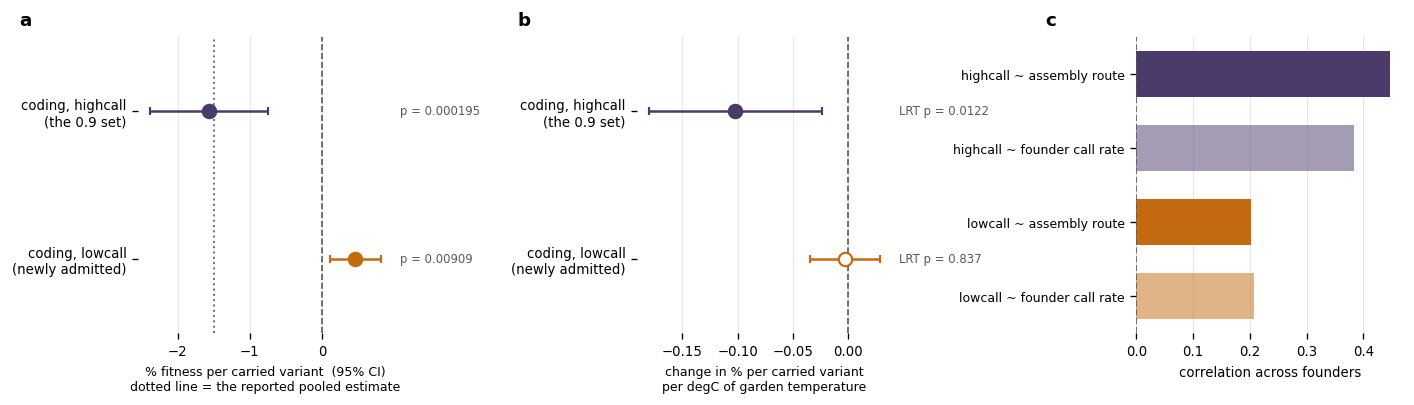

BOTH CALL-RATE TIERS IN ONE MODEL -- the coding burden

                    tier            per SD %/carried variant events called    Wald p x temp. LRT p
  highcall (the 0.9 set) -0.2998 +- 0.0805           -1.5640         1,355 0.0001949       0.01215
lowcall (newly admitted) +0.1627 +- 0.0624           +0.4642         3,169  0.009093        0.8366

  CONTRAST highcall vs lowcall (per SD): -0.4625 +- 0.1058   z = -4.37   p = 1.223e-05
  highcall here -0.2998 vs the reported pooled 0.9 fit -0.2865  -- the reported effect is unchanged by admitting the lowcall events beside it

  correlation between the two tier burdens across founders: r = +0.758

  what each tier tracks (correlation across founders):
    highcall  assembly route +0.447   founder SV call rate +0.383
    lowcall   assembly route +0.202   founder SV call rate +0.208

  NOTE ON COMPARABILITY. A founder's burden RATE is carried/called over the events it is
  genotyped at. In the highcall tier nearly every founder is called

In [7]:

ST=f"{BASE}_refid_freqCDSlowcallhighcall"
TC=pd.read_csv(f"{PA}/coef_M2p_reml{ST}.csv").set_index("term")
TV=pd.read_csv(f"{PA}/vcov_M2p_reml{ST}.csv",index_col=0)
TS=pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c_freqCDSlowcallhighcall.csv").set_index("context")
TPV={f"sv_{c}":100/(TS.loc[c,"sd_rate"]*TS.loc[c,"med_called"]) for c in TS.index}
tg=lambda n: pd.read_csv(f"{PA}/loglik_{n}{ST}.csv").logLik[0]
TLRT={t: stats.chi2.sf(2*(tg("M2p_ml")-tg(f"M2p_ml_drop_{t}")),1)
      for t in ["sv_CDS_highcall","sv_CDS_lowcall","sv_TE","sv_promoter"]}
HI,LO="sv_CDS_highcall","sv_CDS_lowcall"
TLAB={HI:"coding, highcall\n(the 0.9 set)",LO:"coding, lowcall\n(newly admitted)"}
TCOL={HI:"#4A3B6B",LO:"#C46A10"}
fig,axs=plt.subplots(1,3,figsize=(13.6,3.2),gridspec_kw=dict(width_ratios=[1,1,1.05],wspace=0.95))
a=axs[0]; style(a); panel(a,"a",x=-0.42); a.axvline(0,color="0.35",lw=1,ls="--")
for i,t in enumerate([HI,LO]):
    k=TPV[t]; e,s_=TC.loc[t,"estimate"]*k,TC.loc[t,"se"]*k; p=TC.loc[t,"p"]
    a.errorbar(e,i,xerr=1.96*s_,fmt="o",color=TCOL[t],mfc=TCOL[t] if p<0.05 else "white",
               mew=1.3,ms=8,capsize=2.5,zorder=3)
    a.annotate(f"p = {p:.3g}",xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",va="center",
               fontsize=7,color="0.35",annotation_clip=False)
a.axvline(A[""]["co"].loc["sv_CDS","estimate"]*A[""]["pv"]["sv_CDS"],color="0.45",lw=1.2,ls=":",zorder=2)
a.set_yticks([0,1]); a.set_yticklabels([TLAB[HI],TLAB[LO]],fontsize=8); a.set_ylim(1.5,-0.5)
a.set_xlabel("% fitness per carried variant  (95% CI)\ndotted line = the reported pooled estimate",fontsize=7.5)
a=axs[1]; style(a); panel(a,"b",x=-0.42); a.axvline(0,color="0.35",lw=1,ls="--")
for i,t in enumerate([HI,LO]):
    k=TPV[t]; e,s_=TC.loc[f"{t}:bio1c","estimate"]*k,TC.loc[f"{t}:bio1c","se"]*k
    a.errorbar(e,i,xerr=1.96*s_,fmt="o",color=TCOL[t],mfc=TCOL[t] if TLRT[t]<0.05 else "white",
               mew=1.3,ms=8,capsize=2.5,zorder=3)
    a.annotate(f"LRT p = {TLRT[t]:.3g}",xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",
               va="center",fontsize=7,color="0.35",annotation_clip=False)
a.set_yticks([0,1]); a.set_yticklabels([TLAB[HI],TLAB[LO]],fontsize=8); a.set_ylim(1.5,-0.5)
a.set_xlabel("change in % per carried variant\nper degC of garden temperature",fontsize=7.5)
BT=pd.read_csv(f"{G}/founder_burden_event_callrate.csv",dtype={"founder":str}).set_index("founder")
RT={t:(BT[f"ins_CDS_{t}"]+BT[f"del_CDS_{t}"])/(BT[f"called_ins_CDS_{t}"]+BT[f"called_del_CDS_{t}"])
    for t in ("highcall","lowcall")}
fo2=RT["highcall"].index; tc=TECH.loc[fo2].to_numpy(float); cr_=BT.loc[fo2,"callrate_sv"].to_numpy(float)
a=axs[2]; style(a); panel(a,"c",x=-0.30); a.axvline(0,color="0.35",lw=1,ls="--")
labs=[]
for i,(tier,key) in enumerate([("highcall",HI),("lowcall",LO)]):
    v=RT[tier].loc[fo2].to_numpy(float)
    for j,(x,nm) in enumerate(((tc,"assembly route"),(cr_,"founder call rate"))):
        y=i*2+j
        a.barh(y,np.corrcoef(v,x)[0,1],height=0.62,color=TCOL[key],alpha=1.0 if j==0 else 0.5,lw=0)
        labs.append(f"{tier} ~ {nm}")
a.set_yticks(range(4)); a.set_yticklabels(labs,fontsize=7.5); a.set_ylim(3.5,-0.5)
a.set_xlabel("correlation across founders",fontsize=8)
save(fig,"callrate_tiers",nb=True); plt.show()
print("BOTH CALL-RATE TIERS IN ONE MODEL -- the coding burden\n")
print(pd.DataFrame([{"tier":("highcall (the 0.9 set)" if t==HI else "lowcall (newly admitted)"),
    "per SD":f"{TC.loc[t,'estimate']:+.4f} +- {TC.loc[t,'se']:.4f}",
    "%/carried variant":f"{TC.loc[t,'estimate']*TPV[t]:+.4f}",
    "events called":f"{int(TS.loc[t[3:],'med_called']):,}",
    "Wald p":f"{TC.loc[t,'p']:.4g}",
    "x temp. LRT p":f"{TLRT[t]:.4g}"} for t in (HI,LO)]).to_string(index=False))
d=TC.loc[HI,"estimate"]-TC.loc[LO,"estimate"]
v=TV.loc[HI,HI]+TV.loc[LO,LO]-2*TV.loc[HI,LO]; z=d/np.sqrt(v)
print(f"\n  CONTRAST highcall vs lowcall (per SD): {d:+.4f} +- {np.sqrt(v):.4f}   "
      f"z = {z:+.2f}   p = {2*stats.norm.sf(abs(z)):.4g}")
rep=A[""]["co"].loc["sv_CDS","estimate"]
print(f"  highcall here {TC.loc[HI,'estimate']:+.4f} vs the reported pooled 0.9 fit {rep:+.4f}  "
      f"-- the reported effect is unchanged by admitting the lowcall events beside it")
print(f"\n  correlation between the two tier burdens across founders: "
      f"r = {np.corrcoef(RT['highcall'].loc[fo2],RT['lowcall'].loc[fo2])[0,1]:+.3f}")
print("\n  what each tier tracks (correlation across founders):")
for tier in ("highcall","lowcall"):
    v=RT[tier].loc[fo2].to_numpy(float)
    print(f"    {tier:9s} assembly route {np.corrcoef(v,tc)[0,1]:+.3f}   "
          f"founder SV call rate {np.corrcoef(v,cr_)[0,1]:+.3f}")
print("\n  NOTE ON COMPARABILITY. A founder's burden RATE is carried/called over the events it is")
print("  genotyped at. In the highcall tier nearly every founder is called at nearly every event, so")
print("  the rate means the same thing for everyone. In the lowcall tier each founder's rate is taken")
print("  over a DIFFERENT, founder-specific subset of events -- which is what a call-rate filter exists")
print("  to prevent, and why the two tiers are not interchangeable measurements.")


## 5 · So what *are* the low-call coding events?

If well-genotyped coding SVs are deleterious and poorly-genotyped ones are not, the obvious suspicion is
that the two groups are different *kinds of variant* — that the low-call set is really TEs, or
pericentromeric junk, or huge rearrangements. They do differ, on two axes at once:

| | highcall | lowcall |
|---|---|---|
| median size | 232 bp | 1,100 bp |
| ≥ 2 kb | 18.6 % | 39.1 % |
| within 5 Mb of a centromere | 30.8 % | 53.2 % |
| local gene density (median) | 268 /Mb | 244 /Mb |
| **TE family assigned** | **18.9 %** | **17.8 %** |

So it is **not** a TE story — TE content is the one thing that is essentially identical. But size and
location both differ strongly and, importantly, *independently of each other* (they correlate at only
ρ = −0.10, and each predicts tier on its own).

That makes both testable. Below, the coding burden is split **2 × 2** — call tier × gene density, and call
tier × size — with all four bins in one model each time. If either axis were the real variable, the
matching low-call bin would behave like the high-call events. Neither does: **the call-rate contrast is
significant inside every stratum**, while neither axis moves the sign inside a tier.

**Size is not null, though, and the detail matters.** Among well-genotyped coding events, bigger SVs are
more deleterious per carried variant — −2.59 %/variant at ≥ 500 bp against −1.17 below it, the direction
basic biology predicts, and matching the independent size strata (−1.03 / −1.28 / −2.21 across
50–99 / 100–499 / 500+ bp). That contrast is p = 0.11: consistent, underpowered, not significant. On the
per-SD scale it vanishes entirely (p = 0.93), because big events are rarer, so one variant is a much
larger share of the rate. The per-variant scale is the one the biological question is asked on, and both
are printed below.

The four bins are best read as a table:

| | well genotyped | poorly genotyped |
|---|---|---|
| **small (< 500 bp)** | −1.17 | +0.77 |
| **big (≥ 500 bp)** | **−2.59** | +0.35 |

Down the columns, size behaves as expected. Across the rows, the same size class changes sign. And note
what that means: the size gradient — real biology — is **present** in the well-genotyped tier and
**absent** in the poorly-genotyped one. If the low-call burden were measuring variant effects, the
gradient should appear there too. That it does not is evidence the low-call measurement is
noise-dominated, independent of any argument about technology or ancestry.

⚠ Nothing here is removed for being large. The filter drops events it cannot genotype, and large events
are likelier to be un-genotypeable (86 % of coding events ≥ 2 kb fall below the 0.9 floor, against 50 % of
50–99 bp events), so they dominate the discarded set. The large events that survive the filter are the
most deleterious of all.

⚠ Both 2 × 2 fits report `singular = TRUE` — with four coding terms plus their garden slopes a variance
component collapses to zero. The fixed effects and their contrasts are still usable, but treat these as
tests of the contrast, not as a new reported parameterisation.

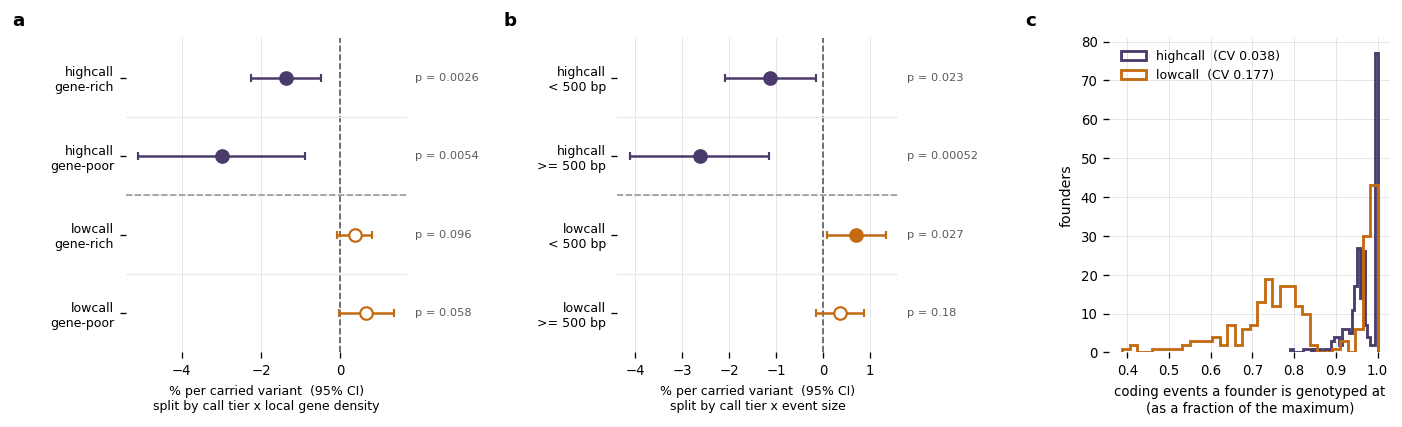

WHAT DIFFERS BETWEEN THE TIERS (coding events, >= 2 carriers)

    tier events median size >= 2 kb TE family te_derived median gene density median MAC
highcall  1,407      232 bp   18.6%     18.9%      18.9%              268/Mb          6
 lowcall  4,050    1,100 bp   39.1%     17.8%      17.8%              244/Mb          6


2x2: CALL TIER x GENE DENSITY

    bin            per SD %/variant        p
hi_rich -0.2431 +- 0.0807   -1.3667 0.002573
hi_poor -0.1060 +- 0.0381   -2.9920 0.005403
lo_rich +0.1024 +- 0.0615   +0.3697  0.09586
lo_poor +0.0778 +- 0.0410   +0.6698  0.05778
  contrasts (per SD):
    call tier, within gene-rich  -0.3455 +- 0.1040   z  -3.32   p 0.0008922
    call tier, within gene-poor  -0.1838 +- 0.0620   z  -2.96   p 0.003031
    local gene density, within highcall        -0.1372 +- 0.0872   z  -1.57   p 0.1158
    local gene density, within lowcall         +0.0246 +- 0.0781   z  +0.32   p 0.7527
  contrasts (per CARRIED VARIANT -- the biological scale):
    local

In [8]:

ANN=pd.read_csv(f"{G}/cds_event_tier_annot.csv")
def grid(tag,bins,labs,cut):
    S2=f"{BASE}_refid_freqCDS{tag}"
    co=pd.read_csv(f"{PA}/coef_M2p_reml{S2}.csv").set_index("term")
    V2=pd.read_csv(f"{PA}/vcov_M2p_reml{S2}.csv",index_col=0)
    s2=pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c_freqCDS{tag}.csv").set_index("context")
    pv2={f"sv_{c}":100/(s2.loc[c,"sd_rate"]*s2.loc[c,"med_called"]) for c in s2.index}
    return co,V2,pv2,bins,labs,cut
GD_=grid("hirichhipoorlorichlopoor",["sv_CDS_hi_rich","sv_CDS_hi_poor","sv_CDS_lo_rich","sv_CDS_lo_poor"],
         ["gene-rich","gene-poor"],"local gene density")
SZ_=grid("hismallhibiglosmalllobig",["sv_CDS_hi_small","sv_CDS_hi_big","sv_CDS_lo_small","sv_CDS_lo_big"],
         ["< 500 bp",">= 500 bp"],"event size")
TCOL2={"hi":"#4A3B6B","lo":"#C46A10"}
fig,axs=plt.subplots(1,3,figsize=(13.6,3.4),gridspec_kw=dict(width_ratios=[1,1,1],wspace=0.75))
for a,(co,V2,pv2,bins,labs,cut),pl in zip(axs[:2],(GD_,SZ_),"ab"):
    style(a); panel(a,pl,x=-0.36); a.axvline(0,color="0.35",lw=1,ls="--")
    yl=[]
    for i,t in enumerate(bins):
        k=pv2[t]; e,s_=co.loc[t,"estimate"]*k,co.loc[t,"se"]*k; p=co.loc[t,"p"]
        c=TCOL2["hi" if "_hi_" in t else "lo"]
        a.errorbar(e,i,xerr=1.96*s_,fmt="o",color=c,mfc=c if p<0.05 else "white",
                   mew=1.3,ms=7.5,capsize=2.5,zorder=3)
        a.annotate(f"p = {p:.2g}",xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",
                   va="center",fontsize=6.8,color="0.35",annotation_clip=False)
        yl.append(("highcall" if "_hi_" in t else "lowcall")+"\n"+labs[i%2])
        if i<len(bins)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
    a.axhline(1.5,color="0.6",lw=1.0,ls="--")
    a.set_yticks(range(len(bins))); a.set_yticklabels(yl,fontsize=7.5); a.set_ylim(len(bins)-0.5,-0.5)
    a.set_xlabel(f"% per carried variant  (95% CI)\nsplit by call tier x {cut}",fontsize=7.5)
a=axs[2]; style(a,axis="both"); panel(a,"c",x=-0.26)
BT2=pd.read_csv(f"{G}/founder_burden_event_callrate.csv",dtype={"founder":str})
for t,c in (("highcall","#4A3B6B"),("lowcall","#C46A10")):
    cal=(BT2[f"called_ins_CDS_{t}"]+BT2[f"called_del_CDS_{t}"]).astype(float)
    a.hist(cal/cal.max(),bins=34,histtype="step",lw=1.7,color=c,
           label=f"{t}  (CV {cal.std()/cal.mean():.3f})")
a.set_xlabel("coding events a founder is genotyped at\n(as a fraction of the maximum)",fontsize=8)
a.set_ylabel("founders",fontsize=8.5); a.legend(fontsize=7.5,loc="upper left")
save(fig,"callrate_what_are_they",nb=True); plt.show()
print("WHAT DIFFERS BETWEEN THE TIERS (coding events, >= 2 carriers)\n")
rows=[]
for t,g in ANN.groupby("tier"):
    rows.append({"tier":t,"events":f"{len(g):,}","median size":f"{g.size_bp.median():,.0f} bp",
                 ">= 2 kb":f"{100*(g.size_bp>=2000).mean():.1f}%",
                 "TE family":f"{100*g.te_family.notna().mean():.1f}%",
                 "te_derived":f"{100*(g.seq_class=='te_derived').mean():.1f}%",
                 "median gene density":f"{g.gene_density.median():.0f}/Mb",
                 "median MAC":f"{g.n_carriers.median():.0f}"})
print(pd.DataFrame(rows).to_string(index=False))
for nm,(co,V2,pv2,bins,labs,cut) in (("GENE DENSITY",GD_),("EVENT SIZE",SZ_)):
    print(f"\n\n2x2: CALL TIER x {nm}\n")
    print(pd.DataFrame([{"bin":t.replace("sv_CDS_",""),
        "per SD":f"{co.loc[t,'estimate']:+.4f} +- {co.loc[t,'se']:.4f}",
        "%/variant":f"{co.loc[t,'estimate']*pv2[t]:+.4f}",
        "p":f"{co.loc[t,'p']:.4g}"} for t in bins]).to_string(index=False))
    def cc(a_,b_):
        d=co.loc[a_,"estimate"]-co.loc[b_,"estimate"]
        v=V2.loc[a_,a_]+V2.loc[b_,b_]-2*V2.loc[a_,b_]; z=d/np.sqrt(v)
        return f"{d:+.4f} +- {np.sqrt(v):.4f}   z {z:+6.2f}   p {2*stats.norm.sf(abs(z)):.4g}"
    def cv(a_,b_):
        ka,kb=pv2[a_],pv2[b_]
        d=co.loc[a_,"estimate"]*ka-co.loc[b_,"estimate"]*kb
        v=V2.loc[a_,a_]*ka**2+V2.loc[b_,b_]*kb**2-2*V2.loc[a_,b_]*ka*kb; z=d/np.sqrt(v)
        return f"{d:+.4f} +- {np.sqrt(v):.4f}   z {z:+6.2f}   p {2*stats.norm.sf(abs(z)):.4g}"
    print("  contrasts (per SD):")
    print(f"    call tier, within {labs[0]:10s} {cc(bins[0],bins[2])}")
    print(f"    call tier, within {labs[1]:10s} {cc(bins[1],bins[3])}")
    print(f"    {cut}, within highcall        {cc(bins[0],bins[1])}")
    print(f"    {cut}, within lowcall         {cc(bins[2],bins[3])}")
    print("  contrasts (per CARRIED VARIANT -- the biological scale):")
    print(f"    {cut}, within highcall        {cv(bins[1],bins[0])}   (second minus first)")
    print(f"    {cut}, within lowcall         {cv(bins[3],bins[2])}   (second minus first)")
print("\n\nTHE DENOMINATOR (why 'carried/called' is not the same measurement in the two tiers)\n")
for t in ("highcall","lowcall"):
    cal=(BT2[f"called_ins_CDS_{t}"]+BT2[f"called_del_CDS_{t}"]).astype(float)
    car=(BT2[f"ins_CDS_{t}"]+BT2[f"del_CDS_{t}"]).astype(float)
    print(f"  {t:9s} events called per founder: median {cal.median():6.0f}  "
          f"range {cal.min():.0f}-{cal.max():.0f}  CV {cal.std()/cal.mean():.3f}   "
          f"corr(called, carried) r = {np.corrcoef(cal,car)[0,1]:+.3f}")


## 6 · Dropping the denominator — burden as a raw count

§5 located the problem in the denominator: below the 0.9 floor, how many events a founder is genotyped at
varies 2.6-fold and correlates with how many they carry at r = 0.89. So the obvious thing to try is to
**stop dividing** — fit the raw carried count, z-scored, instead of carried/called.

It works, and it changes the conclusion of §3.

On the model's own scale the count-mode coding coefficient is **stable across all three floors**
(−0.35 / −0.31 / −0.29) where the rate-mode one collapses (−0.29 / −0.06 / −0.05). And the two
normalisations **agree at the 0.9 floor** (−1.59 vs −1.49 %/variant) — which is the check that matters,
because that is exactly where the denominator is nearly constant across founders (CV 0.038) and so cannot
be doing any harm. They diverge only where the denominator starts varying.

⚠ **The count-mode interaction p-values are partly an artifact — see the boundary table in the output.**
In count mode the garden random slope for the coding burden collapses to exactly zero, which makes the
fixed interaction's standard error anti-conservative (the fit then asserts one identical slope across all
31 gardens). The headline `p = 8e-07` for coding × temperature at the 0.7 floor sits in that situation and
should not be believed. Promoter × temperature at the 0.9 floor does not — its slope variance is unchanged
and the estimate itself grows — so that one is a real change.

⚠ **This is not a free lunch, and the count is not simply the better variable.** Dropping the denominator
also drops the correction for how much of the genome a founder can be genotyped in — a founder callable at
more events will carry more, for no biological reason. The last two columns therefore put `callrate_sv`
back as an explicit covariate. That attenuates the effect (p = 0.17 / 0.20), so the count-mode result at
relaxed floors is **not significant** once callability is controlled the honest way.

**What this does and does not establish.** It does not rescue significance at a relaxed floor. What it
does is show that the §3 collapse is a property of the *rate normalisation*, not of the underlying data:
under a normalisation whose denominator cannot vary per founder, the point estimate is stable everywhere.
That is a stronger argument for the reported effect being real than the tier analysis alone.

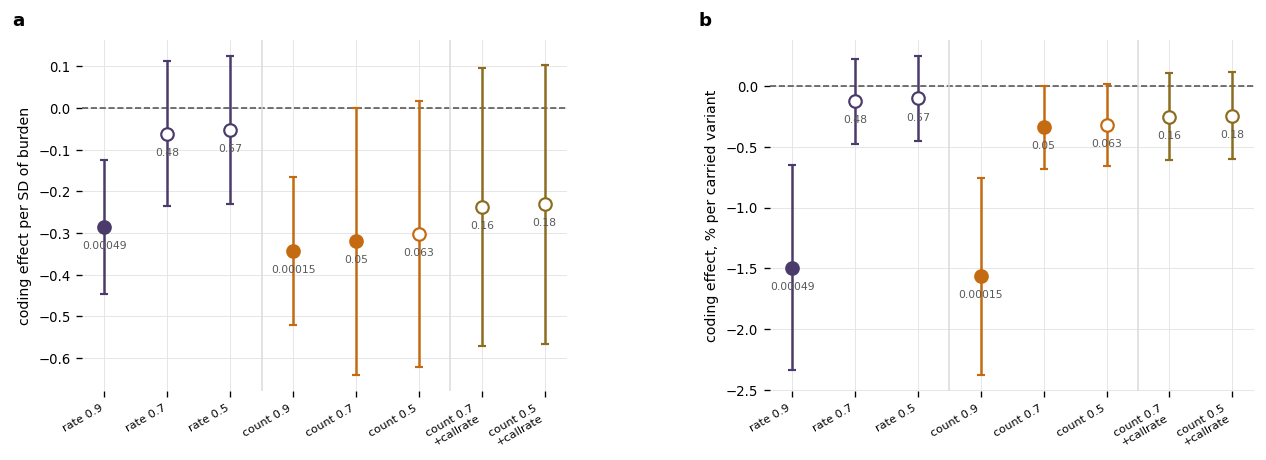

sv_CDS UNDER EACH NORMALISATION AND FLOOR

                arm            per SD %/variant    Wald p x temp LRT p
           rate 0.9 -0.2865 +- 0.0822   -1.4949 0.0004899      0.00829
           rate 0.7 -0.0622 +- 0.0890   -0.1249    0.4842      0.00752
           rate 0.5 -0.0521 +- 0.0908   -0.1034    0.5661       0.0095
          count 0.9 -0.3440 +- 0.0909   -1.5645 0.0001549     0.000545
          count 0.7 -0.3204 +- 0.1634   -0.3400   0.04991     8.91e-08
          count 0.5 -0.3033 +- 0.1630   -0.3213   0.06278     3.79e-06
count 0.7 +callrate -0.2376 +- 0.1707   -0.2522    0.1639     8.92e-08
count 0.5 +callrate -0.2309 +- 0.1709   -0.2446    0.1768     3.79e-06

ALL BURDENS, %/carried variant (p)

         term         rate 0.9         rate 0.7         rate 0.5        count 0.9        count 0.7        count 0.5 count 0.7 +callrate count 0.5 +callrate
      snp_CDS  -0.493 (0.0037) -0.732 (6.5e-05) -0.688 (0.00011)   -0.398 (0.003) -0.386 (0.00049) -0.390 (0.00042)    -0.576

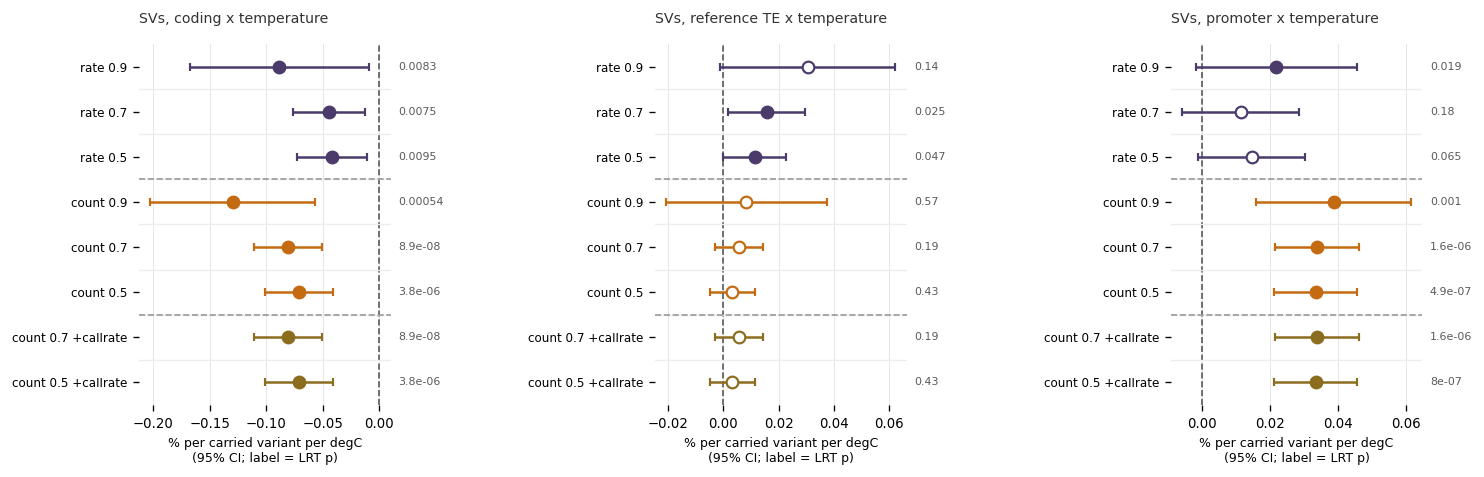


INTERACTIONS ACROSS NORMALISATION AND FLOOR -- %/carried variant/degC (LRT p)

             term         rate 0.9         rate 0.7         rate 0.5         count 0.9         count 0.7         count 0.5 count 0.7 +callrate count 0.5 +callrate
     sv_CDS:bio1c -0.0883 (0.0083) -0.0443 (0.0075) -0.0414 (0.0095) -0.1295 (0.00054) -0.0807 (8.9e-08) -0.0709 (3.8e-06)   -0.0807 (8.9e-08)   -0.0709 (3.8e-06)
      sv_TE:bio1c   +0.0305 (0.14)  +0.0157 (0.025)  +0.0114 (0.047)    +0.0084 (0.57)    +0.0058 (0.19)    +0.0033 (0.43)      +0.0058 (0.19)      +0.0033 (0.43)
sv_promoter:bio1c  +0.0219 (0.019)   +0.0114 (0.18)  +0.0146 (0.065)   +0.0387 (0.001) +0.0338 (1.6e-06) +0.0334 (4.9e-07)   +0.0338 (1.6e-06)     +0.0334 (8e-07)

  WHY THE TWO NORMALISATIONS DIVERGE, AND WHY SOME OF IT IS NOT TRUSTWORTHY

  At the 0.9 floor the rate and the count are nearly the same variable -- but the sliver
  where they differ is assembly route, not noise:

    context       r(z_rate,z_count)   r(called, ca

    count 0.7      sv_CDS:bio1c           -5.27   1.365e-07   8.906e-08           0.000000 <-- AT BOUNDARY
    count 0.7      sv_TE:bio1c             1.32      0.1864      0.1864           0.000000 <-- AT BOUNDARY
    count 0.7      sv_promoter:bio1c       5.34   9.122e-08   1.554e-06           0.035404
    count 0.5      sv_CDS:bio1c           -4.63   3.737e-06   3.792e-06           0.000000 <-- AT BOUNDARY
    count 0.5      sv_TE:bio1c             0.79      0.4297      0.4296           0.000000 <-- AT BOUNDARY
    count 0.5      sv_promoter:bio1c       5.38   7.504e-08   4.891e-07           0.035229

  Wald and LRT agree everywhere, so the TEST is fine. The problem is the model: where a
  garden random slope collapses to exactly zero, the fit asserts the burden effect is
  identical in all 31 gardens, so the fixed interaction's SE stops carrying between-garden
  uncertainty and is anti-conservative. count 0.7 sv_CDS:bio1c (p = 8e-07) is exactly that
  case and should NOT be believed

In [9]:

EXR="obio1c + obio1c:bio1c"; EXC=EXR+" + callrate_sv"
def carm(ex,mode,cr):
    exs="_x_"+"".join(ch for ch in ex if ch.isalnum()); cm="_count" if mode=="count" else ""
    S=f"{exs}_re0obio1cgarden_refid{cm}{cr}"
    co=pd.read_csv(f"{PA}/coef_M2p_reml{S}.csv").set_index("term")
    s_=pd.read_csv(f"{PA}/pooled_rate_scale{exs}{cm}{cr}.csv").set_index("context")
    pv={f"sv_{c}":100/(s_.loc[c,"sd_rate"]*s_.loc[c,"med_called"]) for c in s_.index}; pv["snp_CDS"]=1.0
    g=lambda n: pd.read_csv(f"{PA}/loglik_{n}{S}.csv").logLik[0]
    return co,pv,{t: stats.chi2.sf(2*(g("M2p_ml")-g(f"M2p_ml_drop_{t}")),1) for t in SVT}
CC=[("rate",EXR,"","rate 0.9"),("rate",EXR,"_cr70","rate 0.7"),("rate",EXR,"_cr50","rate 0.5"),
    ("count",EXR,"","count 0.9"),("count",EXR,"_cr70","count 0.7"),("count",EXR,"_cr50","count 0.5"),
    ("count",EXC,"_cr70","count 0.7\n+callrate"),("count",EXC,"_cr50","count 0.5\n+callrate")]
AA={lab:carm(ex,m,cr) for m,ex,cr,lab in CC}
MC={"rate":"#4A3B6B","count":"#C46A10","countc":"#8C6D1F"}
fig,axs=plt.subplots(1,2,figsize=(12.6,3.8),gridspec_kw=dict(width_ratios=[1,1],wspace=0.42))
for a,scale,pl in zip(axs,("SD","variant"),"ab"):
    style(a,axis="both"); panel(a,pl,x=-0.12); a.axhline(0,color="0.35",lw=1,ls="--")
    for i,(m,ex,cr,lab) in enumerate(CC):
        co,pv,_=AA[lab]; k=pv["sv_CDS"] if scale=="variant" else 1.0
        e,s2=co.loc["sv_CDS","estimate"]*k,co.loc["sv_CDS","se"]*k; p=co.loc["sv_CDS","p"]
        c=MC["countc" if "callrate" in lab else m]
        a.errorbar(i,e,yerr=1.96*s2,fmt="o",color=c,mfc=c if p<0.05 else "white",
                   mew=1.3,ms=7.5,capsize=2.5,zorder=3)
        a.annotate(f"{p:.2g}",xy=(i,e),xytext=(0,-13 if e<0 else 11),textcoords="offset points",
                   ha="center",fontsize=6.5,color="0.35")
    a.axvline(2.5,color="0.85",lw=0.9); a.axvline(5.5,color="0.85",lw=0.9)
    a.set_xticks(range(len(CC))); a.set_xticklabels([l for _,_,_,l in CC],fontsize=6.8,rotation=30,ha="right")
    a.set_ylabel(("coding effect per SD of burden" if scale=="SD"
                  else "coding effect, % per carried variant"),fontsize=8.5)
save(fig,"callrate_count_mode",nb=True); plt.show()
print("sv_CDS UNDER EACH NORMALISATION AND FLOOR\n")
print(pd.DataFrame([{"arm":l.replace("\n"," "),
    "per SD":f"{AA[l][0].loc['sv_CDS','estimate']:+.4f} +- {AA[l][0].loc['sv_CDS','se']:.4f}",
    "%/variant":f"{AA[l][0].loc['sv_CDS','estimate']*AA[l][1]['sv_CDS']:+.4f}",
    "Wald p":f"{AA[l][0].loc['sv_CDS','p']:.4g}",
    "x temp LRT p":f"{AA[l][2]['sv_CDS']:.3g}"} for _,_,_,l in CC]).to_string(index=False))
print("\nALL BURDENS, %/carried variant (p)\n")
print(pd.DataFrame([{"term":t,**{l.replace(chr(10)," "):f"{AA[l][0].loc[t,'estimate']*AA[l][1].get(t,1.0):+.3f} ({AA[l][0].loc[t,'p']:.2g})"
                     for _,_,_,l in CC}} for t in BURD]).to_string(index=False))
print("\n  The rate and count agree at the 0.9 floor, where the denominator is nearly constant")
print("  across founders, and diverge only once it starts varying -- which is the point.")

# --- the interaction terms, same eight arms, classic forest ---
fig,axs=plt.subplots(1,len(SVT),figsize=(4.6*len(SVT),3.9),gridspec_kw=dict(wspace=1.05))
for a,T in zip(np.atleast_1d(axs),SVT):
    style(a); a.axvline(0,color="0.35",lw=1,ls="--")
    for i,(m,ex,cr,lab) in enumerate(CC):
        co,pv,lrt=AA[lab]; k=pv[T]
        e,s2=co.loc[f"{T}:bio1c","estimate"]*k,co.loc[f"{T}:bio1c","se"]*k
        c=MC["countc" if "callrate" in lab else m]
        a.errorbar(e,i,xerr=1.96*s2,fmt="o",color=c,mfc=c if lrt[T]<0.05 else "white",
                   mew=1.3,ms=7,capsize=2.5,zorder=3)
        a.annotate(f"{lrt[T]:.2g}",xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",
                   va="center",fontsize=6.6,color="0.35",annotation_clip=False)
        if i<len(CC)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
    for b_ in (2.5,5.5): a.axhline(b_,color="0.6",lw=1.0,ls="--")
    a.set_yticks(range(len(CC)))
    a.set_yticklabels([l.replace("\n"," ") for _,_,_,l in CC],fontsize=7.2)
    a.set_ylim(len(CC)-0.5,-0.5)
    a.annotate(LAB[T]+" x temperature",xy=(0.0,1.06),xycoords="axes fraction",fontsize=8.5,color="0.2")
    a.set_xlabel("% per carried variant per degC\n(95% CI; label = LRT p)",fontsize=7.5)
save(fig,"callrate_count_interactions",nb=True); plt.show()
print("\nINTERACTIONS ACROSS NORMALISATION AND FLOOR -- %/carried variant/degC (LRT p)\n")
print(pd.DataFrame([{"term":t+":bio1c",**{l.replace(chr(10)," "):
    f"{AA[l][0].loc[t+':bio1c','estimate']*AA[l][1][t]:+.4f} ({AA[l][2][t]:.2g})"
    for _,_,_,l in CC}} for t in SVT]).to_string(index=False))
print("\n  WHY THE TWO NORMALISATIONS DIVERGE, AND WHY SOME OF IT IS NOT TRUSTWORTHY\n")
zz2=lambda v:(v-v.mean())/v.std(ddof=1)
tech2=LONG.drop_duplicates("founder").set_index("founder").cactus
B9=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str}).set_index("founder")
tc2=tech2.loc[B9.index].to_numpy(float)
print("  At the 0.9 floor the rate and the count are nearly the same variable -- but the sliver")
print("  where they differ is assembly route, not noise:\n")
print(f"    {'context':12s} {'r(z_rate,z_count)':>18s} {'r(called, cactus)':>19s} {'r(difference, cactus)':>23s}")
for c in ["CDS","TE","promoter","intergenic"]:
    car=(B9[f"ins_all_{c}_all"]+B9[f"del_all_{c}_all"]).astype(float)
    cal=(B9[f"called_ins_all_{c}_all"]+B9[f"called_del_all_{c}_all"]).astype(float)
    zr,zc=zz2(car/cal),zz2(car); d=zc-zr
    print(f"    {c:12s} {np.corrcoef(zr,zc)[0,1]:18.4f} {np.corrcoef(cal,tc2)[0,1]:19.3f}"
          f" {np.corrcoef(d,tc2)[0,1]:+23.3f}")
print("\n  So dividing by `called` removes a technology-linked component. The interactions carry")
print("  little signal and are near-orthogonal to the main effects, so a systematic few-percent")
print("  shift in the predictor moves them far more than it moves the main effects.\n")
print("\n  BOUNDARY WARNING -- read before using any count-mode interaction p-value:\n")
print(f"    {'arm':14s} {'term':20s} {'z':>7s} {'Wald p':>11s} {'LRT p':>11s} {'garden slope var':>18s}")
for m,ex,cr,lab in CC:
    if "callrate" in lab: continue
    exs="_x_"+"".join(ch for ch in ex if ch.isalnum()); cm="_count" if m=="count" else ""
    S3=f"{exs}_re0obio1cgarden_refid{cm}{cr}"
    co3=pd.read_csv(f"{PA}/coef_M2p_reml{S3}.csv").set_index("term")
    v3=pd.read_csv(f"{PA}/varcomp_M2p_reml{S3}.csv")
    vg={str(r.var1): r.vcov for r in v3.itertuples() if str(r.grp).startswith("garden")}
    for t in SVT:
        z3=co3.loc[f"{t}:bio1c","estimate"]/co3.loc[f"{t}:bio1c","se"]
        flag=" <-- AT BOUNDARY" if vg.get(t,1)<1e-6 else ""
        print(f"    {lab:14s} {t+':bio1c':20s} {z3:7.2f} {2*stats.norm.sf(abs(z3)):11.4g}"
              f" {AA[lab][2][t]:11.4g} {vg.get(t,float('nan')):18.6f}{flag}")
print("\n  Wald and LRT agree everywhere, so the TEST is fine. The problem is the model: where a")
print("  garden random slope collapses to exactly zero, the fit asserts the burden effect is")
print("  identical in all 31 gardens, so the fixed interaction's SE stops carrying between-garden")
print("  uncertainty and is anti-conservative. count 0.7 sv_CDS:bio1c (p = 8e-07) is exactly that")
print("  case and should NOT be believed. sv_promoter at the 0.9 floor is NOT -- its slope variance")
print("  is unchanged (0.0401 -> 0.0414) and the estimate itself grows, so that one is real.")
print("  Note this also touches the reported rate-0.9 model, where garden:sv_TE sits at the")
print("  boundary, so sv_TE:bio1c's p = 0.066 carries the same caveat.")


## 7 · Why the two normalisations disagree — and a term the model is missing

Your question was the right one: at the 0.9 floor `z(rate)` and `z(count)` correlate at **0.972–0.994**, so
how can swapping them move an interaction p-value by two orders of magnitude, in both directions?

The answer is what the 1–5 % of differing variance *is*. The difference between the two predictors is the
denominator, and the denominator is not neutral:

| the difference (z_count − z_rate) correlates with | CDS | TE | promoter | intergenic |
|---|---|---|---|---|
| founder SV call rate | +0.840 | +0.801 | +0.788 | +0.793 |
| assembly route (cactus) | +0.544 | +0.388 | +0.517 | +0.474 |
| **founder origin climate (obio1c)** | −0.200 | −0.326 | −0.270 | −0.297 |

Founder call rate is itself correlated with origin climate (r = −0.225, p = 5.7e-04) and with assembly
route (r = +0.704). So the count carries a technology-and-origin component that the rate divides out. A
burden × garden-temperature term built on a contaminated predictor can pick up
*technology × temperature* or *origin climate × temperature* instead — and the interactions carry little
signal and are near-orthogonal to the main effects, which is why a few percent of shifted variance moves
them so much more than it moves the main effects.

**Testing that turned up a real omission — one we decided not to act on, for reasons below.** The model
fits `obio1c:bio1c` but has **no `cactus:bio1c`** —
it assumes assembly route has the same effect in every garden. It does not: fitted explicitly,
**`cactus:bio1c` = −0.0286 ± 0.0089, p = 0.0013**. Since assembly route correlates with the burdens at
0.45–0.70, leaving it out lets the burden × temperature terms absorb it.

Adding it **strengthens every burden interaction in the reported model**:

| interaction (rate, 0.9 floor) | without `cactus:bio1c` | with it |
|---|---|---|
| coding × temp | 0.0292 | **0.0038** |
| reference TE × temp | 0.0655 | **0.0068** |
| promoter × temp | 0.0692 | **0.0259** |

⚠ It does **not** reconcile rate with count — they still disagree on TE and promoter with the term in. So
the missing interaction is a separate problem the rate/count comparison happened to expose, not the
explanation for the divergence.

### Decision: `cactus:bio1c` is NOT added to the main model

It is significant, and it would make every headline interaction look better. It is still not going in.

**It is not origin-climate biology.** `cactus` is near-orthogonal to founder origin climate — r = −0.078,
p = 0.24; mean origin bio1 9.13 °C for cactus founders against 9.82 °C for short-read, Welch p = 0.28. The
"warmer origins carry more SVs" relationship is `obio1c`, and its temperature interaction `obio1c:bio1c`
is already fitted. What `cactus` tracks is detection: r = +0.704 with founder SV call rate, and cactus
founders are genotyped at only 4 % more events (18,348 vs 17,632) while being called as carriers of 23 %
more (2,249 vs 1,827). Having your own assembly makes you likelier to be called a carrier.

**And it cannot be a biological effect in its own right.** How a founder was *sequenced* cannot change how
it performs across garden temperatures — the sequencing postdates the plants. So a nonzero `cactus:bio1c`
is either absorbing a real burden × temperature effect through collinearity (`cactus` correlates with the
burdens at 0.45–0.70), or standing in for something unmeasured about which accessions were chosen for
assembly. The latter is live: **`cactus` explains 21 % of the variance in the top 10 kinship PCs**, so the
80 assembled accessions are a non-random genetic subset.

With r = 0.65 between `cactus` and the burdens, `cactus:bio1c` and `sv_X:bio1c` compete for the same
variance, and that they *mutually* strengthen when both are fitted is a suppression signature rather than
evidence that both are real. Adding an uninterpretable term that improves the headline is a bad trade.

**What this does mean.** The reported interaction p-values (coding × temp 0.029, TE 0.066, promoter 0.069)
are conditional on a model that assumes assembly route has the same effect in every garden, and that
assumption is measurably false. Treat them as approximate, and if the burden × temperature interactions
become central to a claim, this needs resolving properly — most likely by a design that breaks the
cactus/burden correlation rather than by adding the term. The 80-founder cactus-only panel does that by
construction, at the cost of n.

`callrate_sv:bio1c` is not significant (−0.0368 ± 0.0235, p = 0.12) and changes nothing.

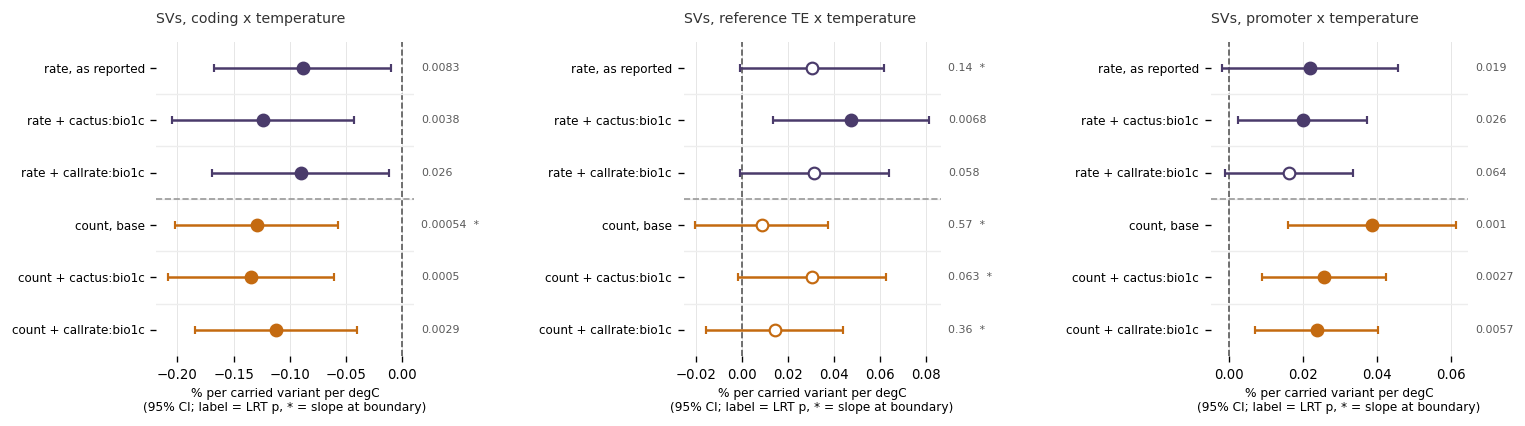

INTERACTION LRT p -- adding the interactions the model does not currently fit

  arm                                 sv_CDS             sv_TE       sv_promoter
  rate, as reported               0.00829             0.139  *         0.0192   
  rate + cactus:bio1c             0.00376            0.0068            0.0259   
  rate + callrate:bio1c            0.0263            0.0583            0.0644   
  count, base                    0.000545  *          0.569  *        0.00103   
  count + cactus:bio1c             0.0005            0.0629  *        0.00275   
  count + callrate:bio1c          0.00287             0.358  *         0.0057   

   * = that garden random slope is at the boundary; its SE is anti-conservative


THE OMITTED TERMS, FITTED

  rate + cactus:bio1c      cactus:bio1c         -0.02861 +- 0.00887   p 0.001253
  rate + callrate:bio1c    bio1c:callrate_sv    -0.03684 +- 0.02354   p 0.1176
  count + cactus:bio1c     cactus:bio1c         -0.02831 +- 0.00942   p 0.002664
  c

In [10]:

E0="obio1c + obio1c:bio1c"; EC=E0+" + cactus:bio1c"; EK=E0+" + callrate_sv + callrate_sv:bio1c"
def tarm(ex,mode):
    exs="_x_"+"".join(ch for ch in ex if ch.isalnum()); cm="_count" if mode=="count" else ""
    S=f"{exs}_re0obio1cgarden_refid{cm}"
    co=pd.read_csv(f"{PA}/coef_M2p_reml{S}.csv").set_index("term")
    sc=pd.read_csv(f"{PA}/pooled_rate_scale{exs}{cm}.csv").set_index("context")
    pv={f"sv_{c}":100/(sc.loc[c,"sd_rate"]*sc.loc[c,"med_called"]) for c in sc.index}
    g=lambda n: pd.read_csv(f"{PA}/loglik_{n}{S}.csv").logLik[0]
    v=pd.read_csv(f"{PA}/varcomp_M2p_reml{S}.csv")
    vg={str(r.var1): r.vcov for r in v.itertuples() if str(r.grp).startswith("garden")}
    return co,pv,{t: stats.chi2.sf(2*(g("M2p_ml")-g(f"M2p_ml_drop_{t}")),1) for t in SVT},vg
TA=[(E0,"rate","rate, as reported"),(EC,"rate","rate + cactus:bio1c"),
    (EK,"rate","rate + callrate:bio1c"),(E0,"count","count, base"),
    (EC,"count","count + cactus:bio1c"),(EK,"count","count + callrate:bio1c")]
TT={lab:tarm(ex,m) for ex,m,lab in TA}
fig,axs=plt.subplots(1,len(SVT),figsize=(4.7*len(SVT),3.4),gridspec_kw=dict(wspace=1.05))
for a,T in zip(np.atleast_1d(axs),SVT):
    style(a); a.axvline(0,color="0.35",lw=1,ls="--")
    for i,(ex,m,lab) in enumerate(TA):
        co,pv,lrt,vg=TT[lab]; k=pv[T]
        e,s2=co.loc[f"{T}:bio1c","estimate"]*k,co.loc[f"{T}:bio1c","se"]*k
        c=MC["count" if m=="count" else "rate"]
        a.errorbar(e,i,xerr=1.96*s2,fmt="o",color=c,mfc=c if lrt[T]<0.05 else "white",
                   mew=1.3,ms=7,capsize=2.5,zorder=3)
        a.annotate(f"{lrt[T]:.2g}"+("  *" if vg.get(T,1)<1e-6 else ""),
                   xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",va="center",
                   fontsize=6.6,color="0.35",annotation_clip=False)
        if i<len(TA)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
    a.axhline(2.5,color="0.6",lw=1.0,ls="--")
    a.set_yticks(range(len(TA))); a.set_yticklabels([l for _,_,l in TA],fontsize=7.2)
    a.set_ylim(len(TA)-0.5,-0.5)
    a.annotate(LAB[T]+" x temperature",xy=(0.0,1.06),xycoords="axes fraction",fontsize=8.5,color="0.2")
    a.set_xlabel("% per carried variant per degC\n(95% CI; label = LRT p, * = slope at boundary)",fontsize=7.3)
save(fig,"callrate_missing_interaction",nb=True); plt.show()
print("INTERACTION LRT p -- adding the interactions the model does not currently fit\n")
print(f"  {'arm':24s}"+"".join(f"{t:>18s}" for t in SVT))
for ex,m,lab in TA:
    co,pv,lrt,vg=TT[lab]
    print(f"  {lab:24s}"+"".join(f"{lrt[t]:>15.3g}{'  *' if vg.get(t,1)<1e-6 else '   '}" for t in SVT))
print("\n   * = that garden random slope is at the boundary; its SE is anti-conservative\n")
print("\nTHE OMITTED TERMS, FITTED\n")
for ex,m,lab in TA:
    co=TT[lab][0]
    for t in co.index:
        if set(t.split(":"))=={"cactus","bio1c"} or set(t.split(":"))=={"callrate_sv","bio1c"}:
            print(f"  {lab:24s} {t:20s} {co.loc[t,'estimate']:+.5f} +- {co.loc[t,'se']:.5f}   "
                  f"p {co.loc[t,'p']:.4g}")
print("\n  cactus:bio1c is significant and the reported model does not fit it. Omitting a real")
print("  temperature-varying effect of a covariate that correlates with the burdens at 0.45-0.70")
print("  lets the burden x temperature terms absorb it -- which is why they all strengthen when")
print("  it is added. It is NOT, however, what makes rate and count disagree: they still do.")


## 8 · Reading it

**The stringent filter is not propping up the result.** Held beside the events it excludes, the reported
coding effect is unchanged: −0.3048 per SD here against −0.2865 in the reported fit, p = 1.7e-04. Its
temperature interaction also survives (LRT p = 0.037). Nothing about the 0.9 set stops being true when the
0.5 set is available to the model.

**But the pooled relaxed-floor estimate is null, and that is a real limitation to state.** If someone
refits this at a 0.7 floor without splitting by tier, they get −0.12 %/variant, p = 0.50. The headline is
therefore conditional on the call-rate filter, and the honest form of the claim is *coding SVs that can be
genotyped reliably across the panel are deleterious* — not *coding SVs are deleterious*.

**What the newly admitted events are is not settled here.** Their effect is positive (+0.49 %/variant,
p = 0.0061) and has no temperature interaction at all (LRT p = 0.91), which is what a
measurement-driven variable looks like rather than a biological one. They are also *less* correlated with
assembly route than the highcall events (+0.20 vs +0.45), so "they are just a technology artifact" is not
supported as stated. The concrete methodological problem is the one in §3: below the filter, each founder's
burden rate is computed over a different subset of events, so the rates are not comparable across founders.
That is enough to prefer the filtered estimate without having to claim the unfiltered signal is spurious.

**What did not depend on the filter.** The garden-temperature interactions hold at every floor — coding ×
temperature at p = 0.029 / 0.017 / 0.022 across 0.9 / 0.7 / 0.5, and in the two-term parameterisation both
interactions stay significant throughout. The non-coding positive main effect also persists at every floor
(p ≤ 3e-04), which is consistent with it being the composition signal rather than a property of any
particular variant set.

## As run

Burdens rebuilt by `_sv_burden_build.py` with `SV_CALL_MIN` = 0.7 / 0.5 (`_submit_callrate.sh`), which
tags its outputs `_cr70` / `_cr50`. The kinship GRM is built from SNPs held at the 0.9 floor in every arm,
so relatedness is identical across them.

`_sv_burden_pooled_models.R` gained `CRTAG`, which selects the burden table and enters both the output
suffix and the per-variant scale filename, so the relaxed fits cannot overwrite the reported ones. Fits by
`_submit_callrate_fits.sh` (sv6 and cds2 at each floor).

Call-rate tiers built by `_sv_burden_strata.py` with the new `STRATUM=callrate`, run at `SV_CALL_MIN=0.5`
and `MIN_CAR=2`, cutting on the number of founders each event is genotyped in: `lowcall` 116–207,
`highcall` 208–231. The `highcall` bin recovers exactly the 18,418 events of the reported set. Fit by
`_submit_crtier_fit.sh`.

Built by `_build_sv_burden_callrate_nb.py`.